In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
df = pd.read_csv("https://raw.githubusercontent.com/nanasbubu/analisis-loan-approval/main/loan_data.csv")
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [19]:
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
count,45000.000000,45000,45000,4.500000e+04,45000.000000,45000,45000.000000,45000,45000.000000,45000.000000,45000.000000,45000.000000,45000,45000.000000
unique,NaN,2,5,NaN,NaN,4,NaN,6,NaN,NaN,NaN,NaN,2,NaN
top,NaN,male,Bachelor,NaN,NaN,RENT,NaN,EDUCATION,NaN,NaN,NaN,NaN,Yes,NaN
freq,NaN,24841,13399,NaN,NaN,23443,NaN,9153,NaN,NaN,NaN,NaN,22858,NaN
mean,27.764178,NaN,NaN,8.031905e+04,5.410333,NaN,9583.157556,NaN,11.006606,0.139725,5.867489,632.608756,NaN,0.222222
std,6.045108,NaN,NaN,8.042250e+04,6.063532,NaN,6314.886691,NaN,2.978808,0.087212,3.879702,50.435865,NaN,0.415744
min,20.000000,NaN,NaN,8.000000e+03,0.000000,NaN,500.000000,NaN,5.420000,0.000000,2.000000,390.000000,NaN,0.000000
25%,24.000000,NaN,NaN,4.720400e+04,1.000000,NaN,5000.000000,NaN,8.590000,0.070000,3.000000,601.000000,NaN,0.000000
50%,26.000000,NaN,NaN,6.704800e+04,4.000000,NaN,8000.000000,NaN,11.010000,0.120000,4.000000,640.000000,NaN,0.000000
75%,30.000000,NaN,NaN,9.578925e+04,8.000000,NaN,12237.250000,NaN,12.990000,0.190000,8.000000,670.000000,NaN,0.000000


In [20]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

,0


karena missing value tidak ada maka tidak perlu proses lanjutan

In [25]:
print("Usia > 100:", (df["person_age"] > 100).sum())
df = df[df["person_age"] <= 100].copy()

Usia > 100: 7


In [26]:
df = df.drop(columns=["person_emp_exp"])

usia lebih dari 100 dihitung tidak masuk akal (outlier) jadi dihapus

In [28]:
num_cols = df.drop(columns="loan_status").select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

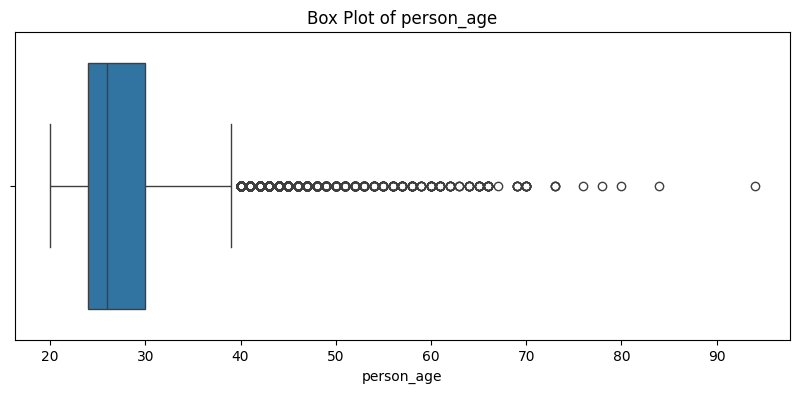

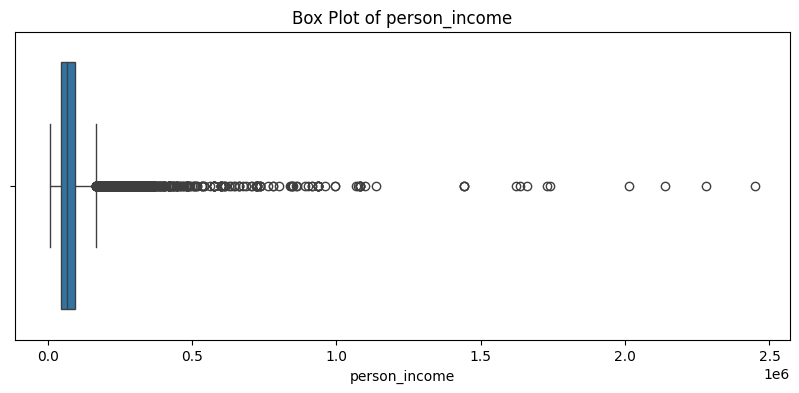

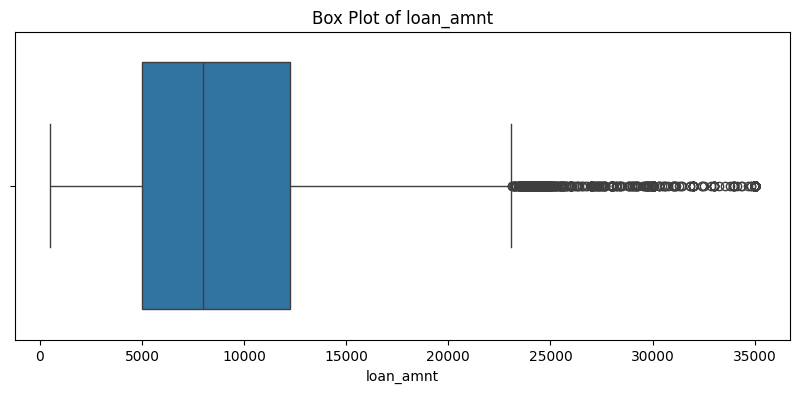

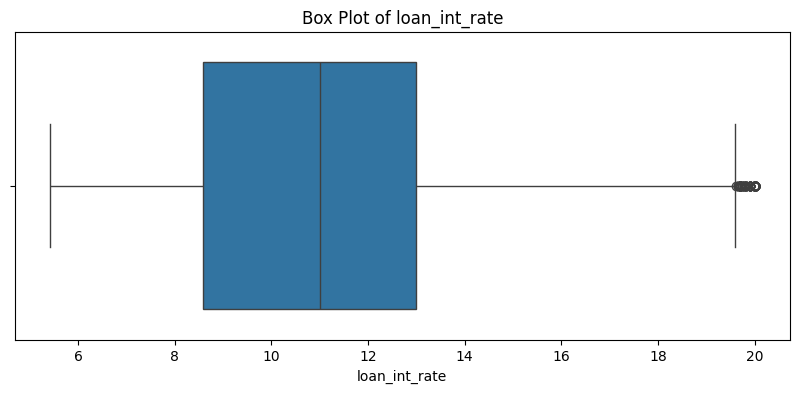

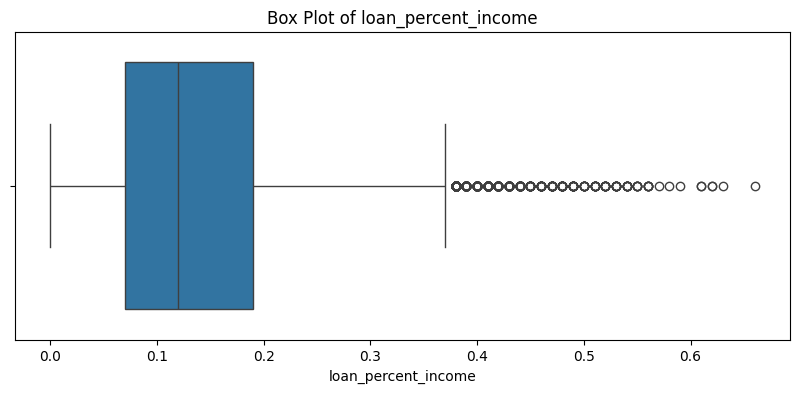

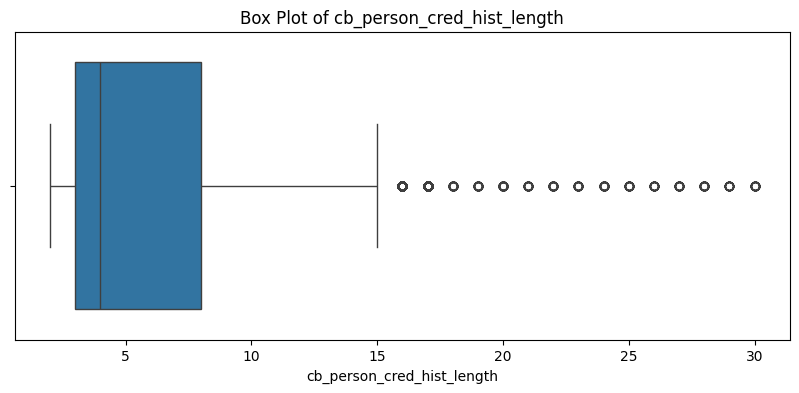

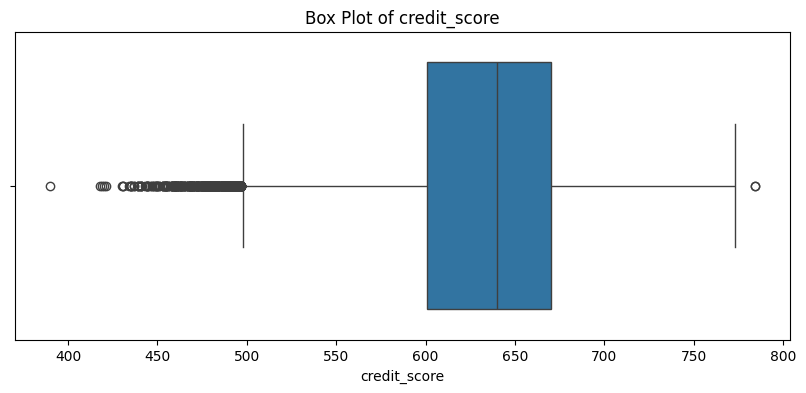

In [29]:
for col in num_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

titik di luar whisker hitungannya outlier, paling banyak ada di loan_amnt

In [30]:
#batas outlier pake metode iqr
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [31]:
is_outlier = (df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)
print("Baris outlier:", is_outlier.any(axis=1).sum(), "dari", len(df))

Baris outlier: 7376 dari 44993


In [32]:
df[num_cols] = df[num_cols].clip(lower=lower_bound, upper=upper_bound, axis=1)

In [33]:
print("Duplikat:", df.duplicated().sum())

Duplikat: 0


karena duplikat tidak ada maka tidak perlu proses lanjutan

In [34]:
df_onehot = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
df_onehot.head()

,person_age,person_income,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status,person_gender_male,person_education_Bachelor,...,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
0,22.0,71948.0,23092.5,16.02,0.37,3.0,561.0,1,0,0,...,1,0,0,1,0,0,0,1,0,0
1,21.0,12282.0,1000.0,11.14,0.08,2.0,504.0,0,0,0,...,0,0,1,0,1,0,0,0,0,1
2,25.0,12438.0,5500.0,12.87,0.37,3.0,635.0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,23.0,79753.0,23092.5,15.23,0.37,2.0,675.0,1,0,1,...,0,0,0,1,0,0,1,0,0,0
4,24.0,66135.0,23092.5,14.27,0.37,4.0,586.0,1,1,0,...,1,0,0,1,0,0,1,0,0,0


pakai one hot encoding karena data kategorikal

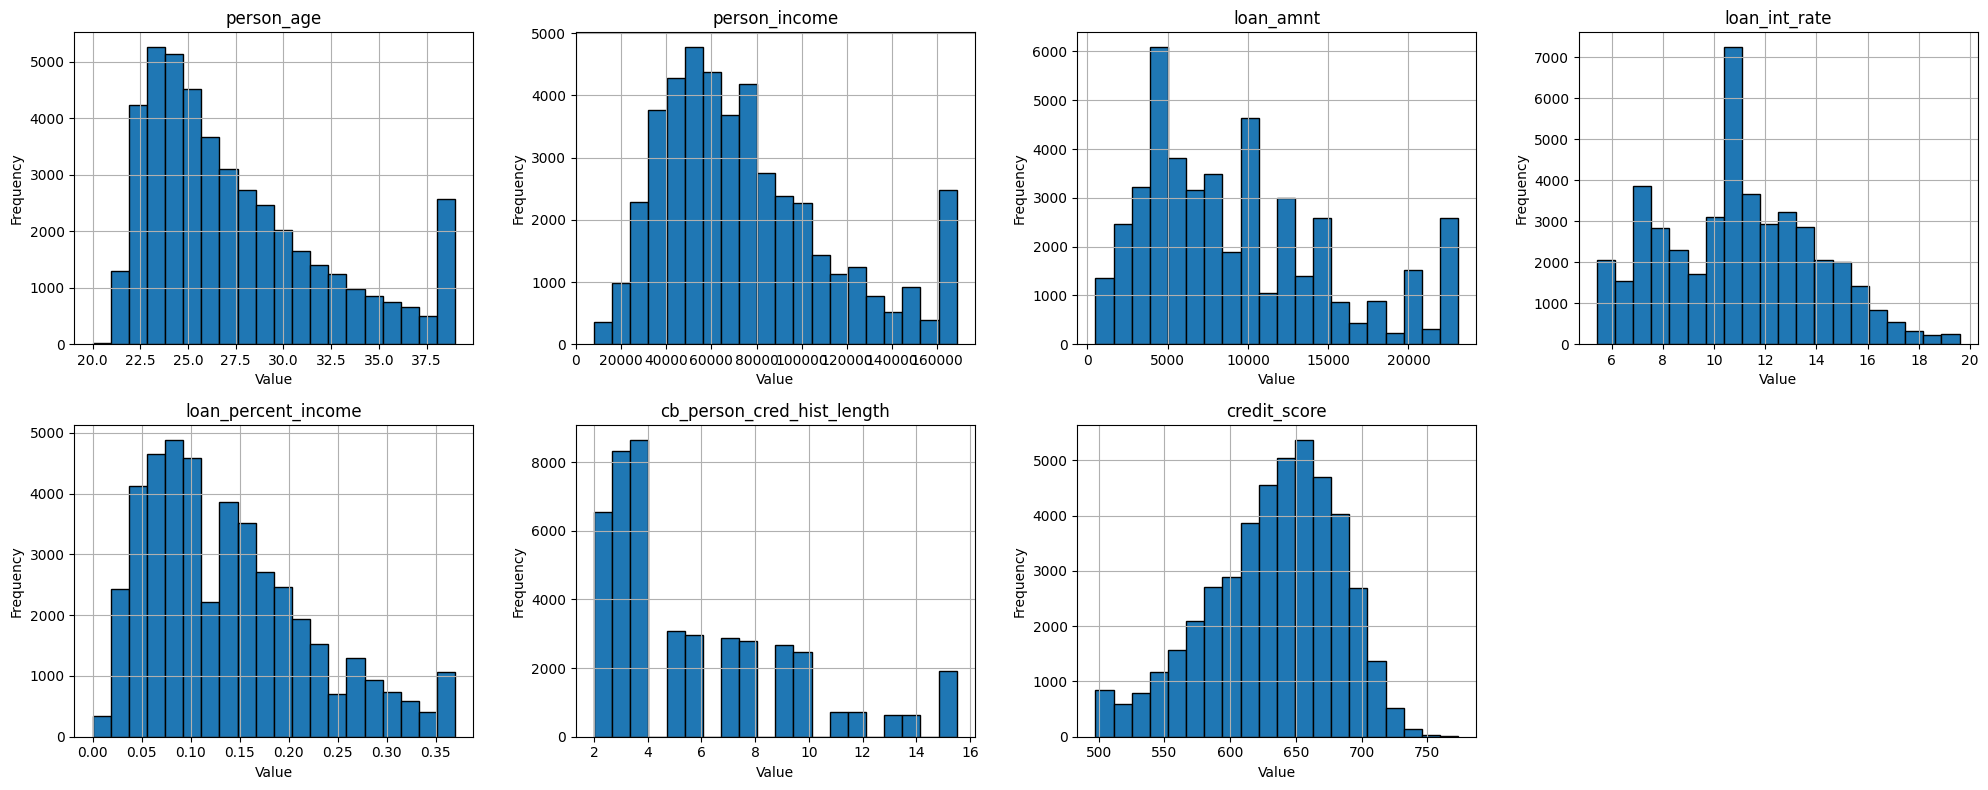

In [38]:
n_cols = 4
n_rows = -(-len(num_cols) // n_cols) #pembulatan ke atas
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df[col].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

setelah capping, kebanyakan skewness variable masih condong ke kanan. cuma loan_int_rate dan credit_score yang bentuknya cukup simetris

loan_status
0    34993
1    10000
Name: count, dtype: int64


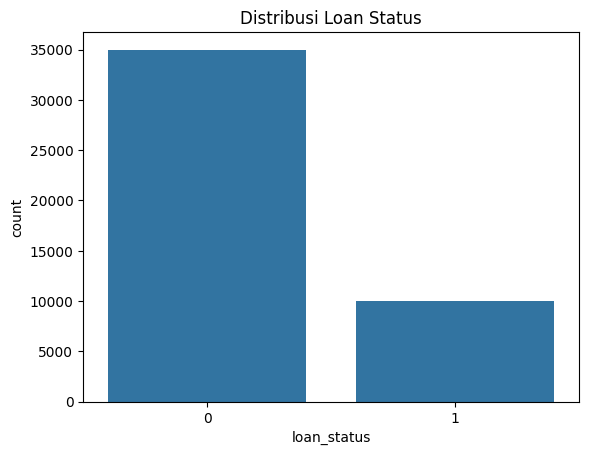

In [39]:
print(df["loan_status"].value_counts())
sns.countplot(x="loan_status", data=df)
plt.title("Distribusi Loan Status")
plt.show()

data tidak seimbang, maka menggunakan smote sebagai metode modelling

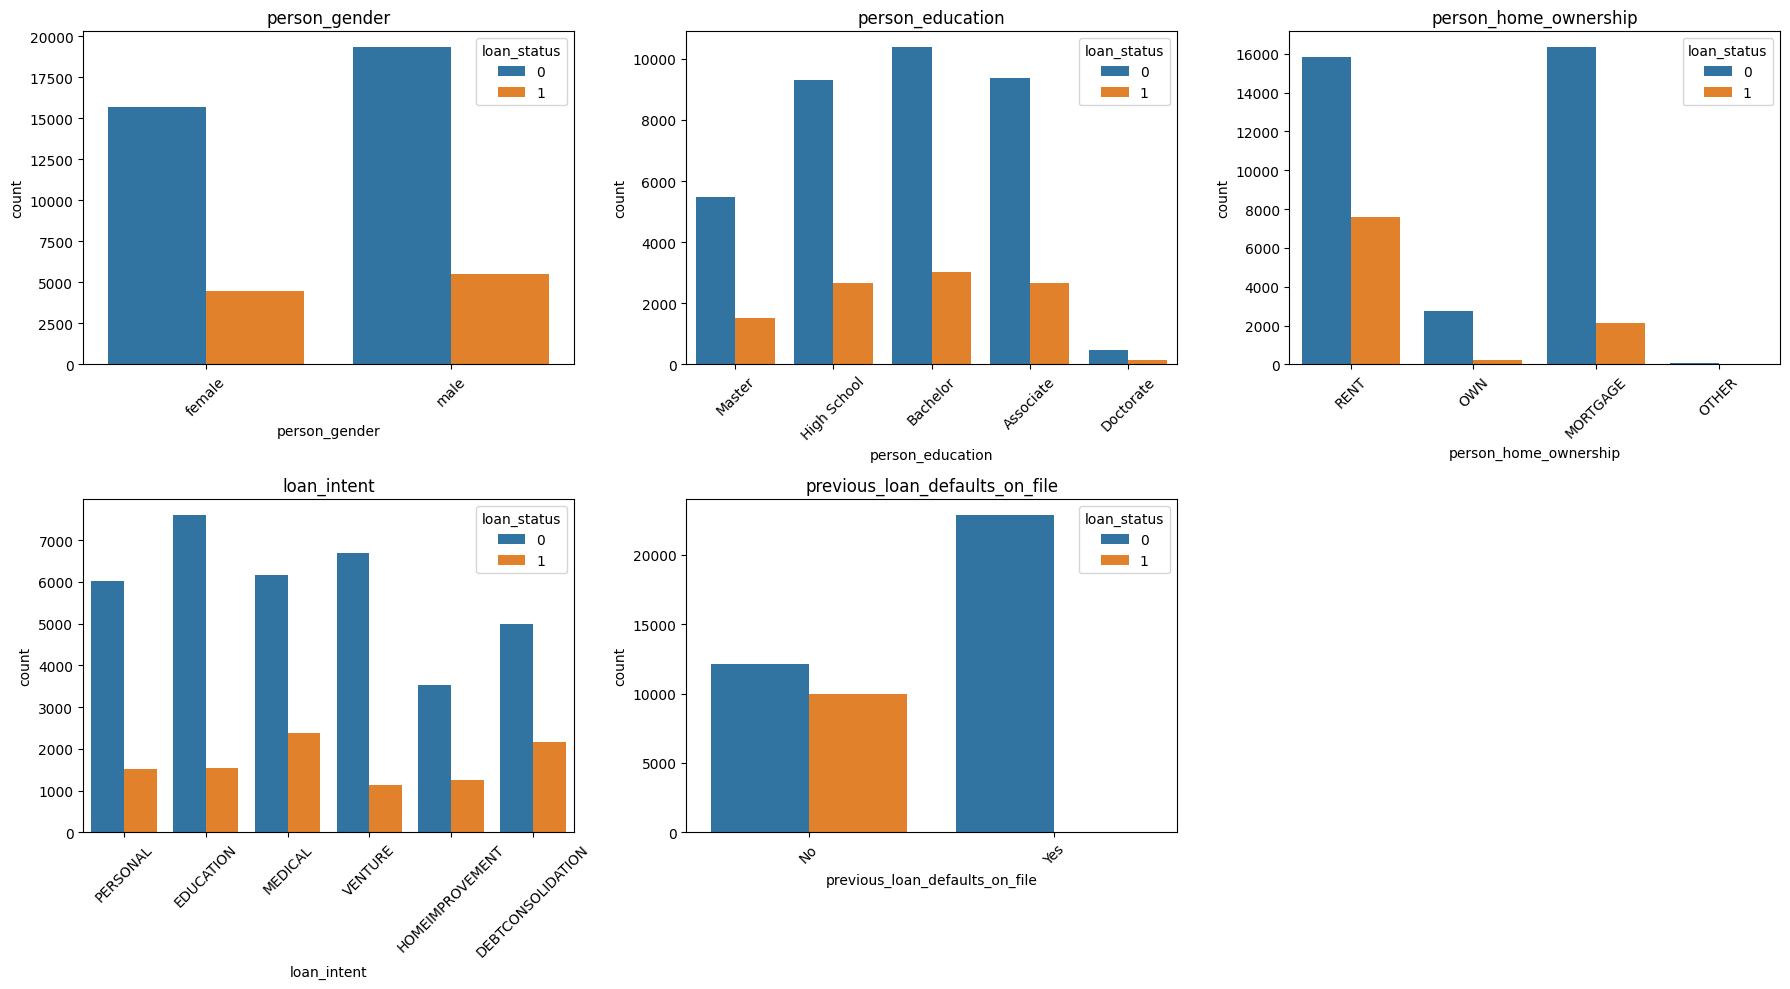

In [40]:
plt.figure(figsize=(18, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(2, 3, i)
    sns.countplot(x=col, hue="loan_status", data=df)
    plt.xticks(rotation=45)
    plt.title(col)
plt.tight_layout()
plt.show()

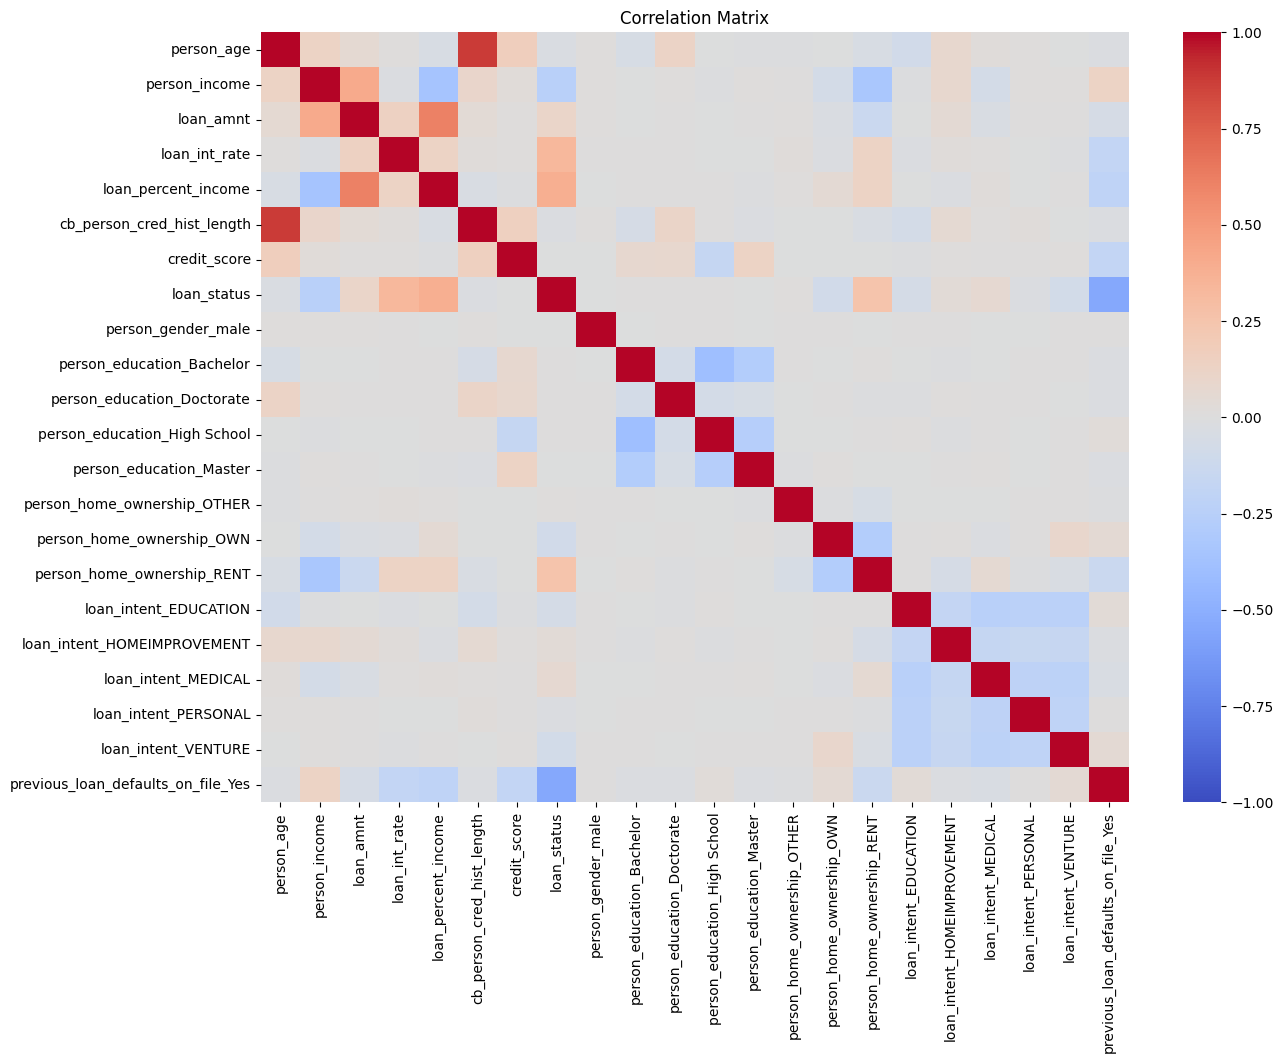

In [42]:
#matriks korelasi antar variabel
plt.figure(figsize=(14, 10))
correlation_matrix = df_onehot.corr()
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

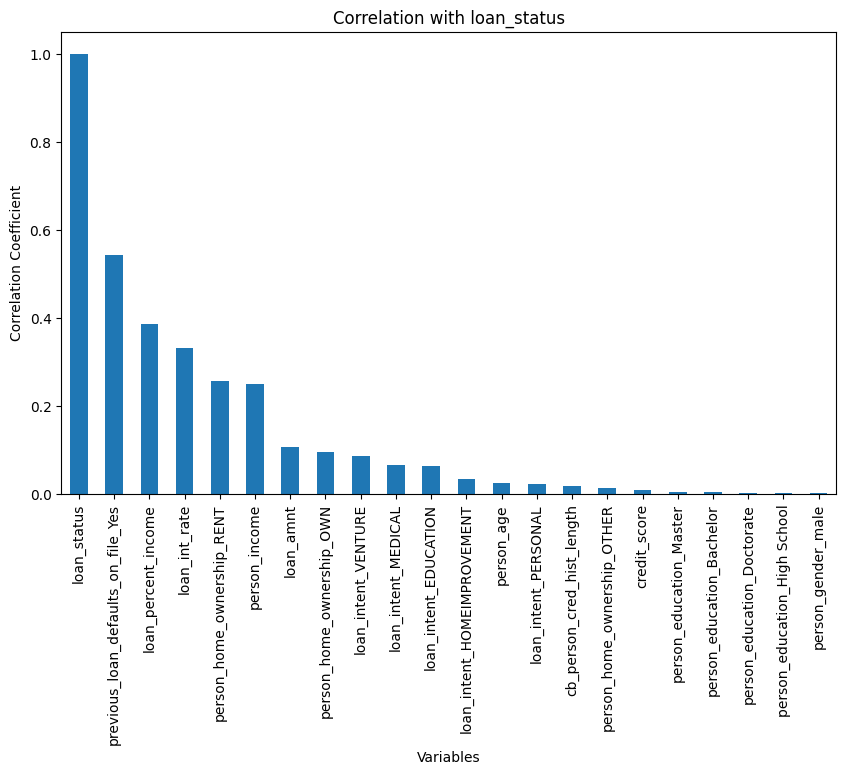

In [43]:
#korelasi setiap variabel terhadap loan_status
target_corr = df_onehot.corr()["loan_status"].abs().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
target_corr.plot(kind="bar")
plt.title("Correlation with loan_status")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.show()

In [45]:
from sklearn.model_selection import train_test_split

X = df_onehot.drop(columns=["loan_status"])
y = df_onehot["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah data:", len(X))
print("Jumlah data latih:", len(X_train))
print("Jumlah data test:", len(X_test))

Jumlah data: 44993
Jumlah data latih: 35994
Jumlah data test: 8999


menggunakan stratify sehingga menjaga proporsi kelas di data train dan test

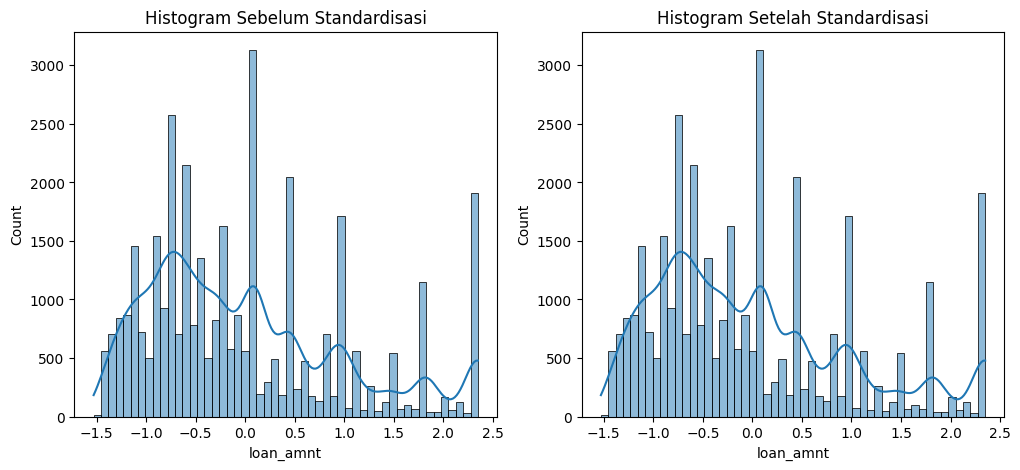

In [47]:
from sklearn.preprocessing import StandardScaler

before_scaling = X_train["loan_amnt"].copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(before_scaling, kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.subplot(1, 2, 2)
sns.histplot(X_train["loan_amnt"], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

scaling ditukar jadi setelah split supaya data uji tidak ikut mempengaruhi rata rata dan simpangan baku

hasil analisis: bentuk histogramnya sama persis, yang berubah hanya skala loan_amnt

In [49]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(y_train_smote.value_counts())

loan_status
0    27994
1    27994
Name: count, dtype: int64


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10,
                                            min_samples_split=4, min_samples_leaf=4,
                                            random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                             subsample=0.8, random_state=42, eval_metric="logloss"),
}

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)

dalam kasus ini merupakan klasifikasi (karena targetnya biner 0/1). ada 4 model: logistic regression jadi model pembanding dasar; random forest, gradient boosting dan XGBoost berbasis pohon keputusan untuk menangkap hubungan antar fitur

In [54]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, proba),
    ]

df_results = pd.DataFrame(results, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).T
df_results.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8623,0.6335,0.9030,0.7446,0.9504
Random Forest,0.8928,0.6991,0.9085,0.7902,0.9698
Gradient Boosting,0.8905,0.6962,0.9005,0.7853,0.9685
XGBoost,0.9178,0.7893,0.8595,0.8229,0.9727


XGBoost paling unggul dengan accuracy 0,918, F1 0,823, dan ROC-AUC 0,973. Logistic Regression paling rendah (accuracy 0,862, F1 0,745), wajar karena hubungan antar fiturnya tidak sepenuhnya linear. Random Forest dan Gradient Boosting hasilnya berdekatan (F1 sekitar 0,79). Karena datanya tidak seimbang, F1 dan ROC-AUC lebih layak dijadikan acuan daripada accuracy saja.

hasil analisis: XGBoost paling unggul

In [55]:
import joblib
joblib.dump(models["XGBoost"], "loan_model.joblib")

['loan_model.joblib']